## 1. Import libraries

In [1]:
import os, re, pickle
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential, layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load the dataset

Same Kaggle dataset as before. If Kaggle download fails (no internet / no access), the code falls back to
a small built-in text so the notebook still runs. You can also upload your own `.txt` file in Colab and set `LOCAL_TXT`.

In [2]:
LOCAL_TXT = None   # e.g. "mybook.txt" if you uploaded your own file

FALLBACK_TEXT = '''
Machine learning is a branch of artificial intelligence that focuses on building systems that learn from data.
Deep learning is a subset of machine learning that uses neural networks with many layers.
A neural network is made of layers of connected nodes that process information.
Recurrent neural networks are designed to work with sequences such as text and speech.
Long short term memory networks solve the problem of vanishing gradients in recurrent networks.
An LSTM cell uses gates to decide what information to keep and what information to forget.
Natural language processing allows computers to understand and generate human language.
Next word prediction is a task where the model predicts the next word in a sentence.
The model learns the patterns of language by reading a large amount of text.
To train the model we convert words into numbers and feed the sequences into the network.
The embedding layer turns each word into a dense vector that captures its meaning.
The output layer uses a softmax function to give a probability for every word in the vocabulary.
The word with the highest probability is chosen as the predicted next word.
Training a neural network requires data and a loss function and an optimizer.
The optimizer updates the weights of the network to reduce the loss.
A good model should perform well on data that it has never seen before.
Students learn machine learning by building small projects and practicing every day.
Python is the most popular programming language for machine learning and data science.
Keras is a simple and powerful library for building deep learning models in Python.
'''

def load_raw_text():
    if LOCAL_TXT:
        path = LOCAL_TXT
    else:
        try:
            import kagglehub
            folder = kagglehub.dataset_download("ronikdedhia/next-word-prediction")
            files = [f for f in os.listdir(folder) if f.endswith(".txt")]
            path = os.path.join(folder, files[0])
            print("Dataset file:", path)
        except Exception as e:
            print("Kaggle download failed -> using fallback text.\nReason:", e)
            return FALLBACK_TEXT
    # try utf-8 first, then charmap (the original notebook used charmap)
    for enc in ("utf-8", "charmap"):
        try:
            with open(path, "r", encoding=enc, errors="ignore") as f:
                return f.read()
        except Exception:
            continue

raw_text = load_raw_text()
print("Characters in raw text:", len(raw_text))
print(raw_text[:300])

Using Colab cache for faster access to the 'next-word-prediction' dataset.
Dataset file: /kaggle/input/next-word-prediction/1661-0.txt
Characters in raw text: 581888
﻿
Project Gutenberg's The Adventures of Sherlock Holmes, by Arthur Conan Doyle

This eBook is for the use of anyone anywhere at no cost and with
almost no restrictions whatsoever.  You may copy it, give it away or
re-use it under the terms of the Project Gutenberg License included
with this eBook or


## 3. Clean the text

**What was wrong earlier:** the old code removed *every* character except letters and spaces, including the full stops.
Because of that, `sent_tokenize` could not find sentence boundaries and the whole book became one giant sentence.
Now we keep `. ! ?` first, split into sentences, and only then remove other symbols.

We also **do not lemmatize**: lemmatizing changes words (e.g. *going → going, was → wa*), so the model would learn and predict wrong word forms.

In [3]:
def clean_and_split(text, min_words=3, max_words=40, max_sentences=60000):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)                  # newlines/tabs -> single space
    text = re.sub(r"[^a-z\s\.\!\?']", " ", text)      # keep letters, spaces, . ! ? and apostrophe
    sentences = re.split(r"[\.\!\?]+", text)          # split into sentences
    sentences = [re.sub(r"\s+", " ", s).strip() for s in sentences]
    sentences = [s for s in sentences if min_words <= len(s.split()) <= max_words]
    return sentences[:max_sentences]

sentences = clean_and_split(raw_text)
print("Number of sentences:", len(sentences))
print("Example:", sentences[0])

Number of sentences: 6374
Example: project gutenberg's the adventures of sherlock holmes by arthur conan doyle this ebook is for the use of anyone anywhere at no cost and with almost no restrictions whatsoever


## 4. Tokenization (word → integer)

In [4]:
tokenizer = Tokenizer(oov_token=None)
tokenizer.fit_on_texts(sentences)

vocab_size = len(tokenizer.word_index) + 1     # +1 because index 0 is used for padding
index_to_word = {i: w for w, i in tokenizer.word_index.items()}
print("Vocabulary size:", vocab_size)

Vocabulary size: 7441


## 5. Create input sequences (n-grams)

For the sentence `i like green tea` we create:

| input (X) | label (y) |
|---|---|
| i | like |
| i like | green |
| i like green | tea |

(The old code skipped the last words of every sentence and had the wrong loop range. This fixes that.)

In [5]:
input_sequences = []
for sentence in sentences:
    token_list = tokenizer.texts_to_sequences([sentence])[0]
    for i in range(2, len(token_list) + 1):
        input_sequences.append(token_list[:i])

max_len = max(len(s) for s in input_sequences)
print("Total sequences:", len(input_sequences))
print("Longest sequence:", max_len)

Total sequences: 86916
Longest sequence: 40


## 6. Padding and split into X, y

- `padding='pre'` puts zeros at the **start**, so the LSTM's last step sees real words (the old `post` padding hurts LSTM).
- `y` stays a 1-D integer array (the old code accidentally replaced `y` with a *shape tuple*, which broke training).

In [6]:
input_sequences = pad_sequences(input_sequences, maxlen=max_len, padding="pre")

X = input_sequences[:, :-1]     # all words except the last
y = input_sequences[:, -1]      # last word = word to predict

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test :", X_test.shape,  "y_test :", y_test.shape)

X_train: (73878, 39) y_train: (73878,)
X_test : (13038, 39) y_test : (13038,)


## 7. Build the LSTM model

**What was wrong earlier:**
- No `Embedding` layer: raw word IDs (like 4521) were fed to the LSTM as if they were numbers with meaning. Embedding gives each word a learnable vector.
- Output size was hard-coded as `8646`; now it is `vocab_size` so it always matches the data.
- Input shape was hard-coded as `(251, 1)`; now it comes from the data.

In [7]:
model = Sequential([
    layers.Input(shape=(max_len - 1,)),
    layers.Embedding(input_dim=vocab_size, output_dim=128),
    layers.LSTM(256, return_sequences=True),
    layers.Dropout(0.3),
    layers.LSTM(128),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dense(vocab_size, activation="softmax"),
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy", tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_acc")],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 39, 128)        │       952,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 39, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 39, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7441)           │     1,912,337 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,489,169 (13.31 MB)

 Trainable params: 3,489,169 (13.31 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Train the model

In [8]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=30,            # the old code used only 1 epoch; EarlyStopping stops sooner if needed
    batch_size=128,
    callbacks=callbacks,
)

Epoch 1/30
520/520 ━━━━━━━━━━━━━━━━━━━━ 16s 17ms/step - accuracy: 0.0559 - loss: 6.5582 - top5_acc: 0.1605 - val_accuracy: 0.0635 - val_loss: 6.2723 - val_top5_acc: 0.1738 - learning_rate: 0.0010
Epoch 2/30
520/520 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.0721 - loss: 6.0870 - top5_acc: 0.1969 - val_accuracy: 0.0836 - val_loss: 6.0722 - val_top5_acc: 0.2267 - learning_rate: 0.0010
Epoch 3/30
520/520 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.0913 - loss: 5.7945 - top5_acc: 0.2412 - val_accuracy: 0.0934 - val_loss: 5.9854 - val_top5_acc: 0.2588 - learning_rate: 0.0010
Epoch 4/30
520/520 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.1049 - loss: 5.5985 - top5_acc: 0.2650 - val_accuracy: 0.1004 - val_loss: 5.9287 - val_top5_acc: 0.2696 - learning_rate: 0.0010
Epoch 5/30
520/520 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.1181 - loss: 5.4462 - top5_acc: 0.2795 - val_accuracy: 0.1138 - val_loss: 5.8938 - val_top5_acc: 0.2811 - learning_rate: 0.0010
Epoch 6/30
520/520 ━━━━

## 9. Evaluate and plot

Test loss: 5.9061 | Test accuracy: 12.80% | Top-5 accuracy: 29.03%


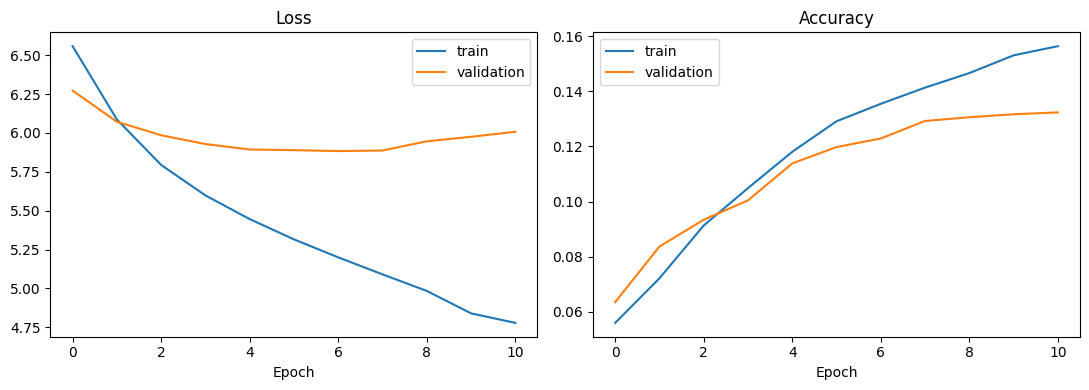

In [9]:
loss, acc, top5 = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss: {loss:.4f} | Test accuracy: {acc*100:.2f}% | Top-5 accuracy: {top5*100:.2f}%")

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

## 10. Predict the next word

`predict_next_words` returns the top-k most likely words with their probabilities.
`generate_text` keeps predicting to build a longer sentence.

In [10]:
def clean_input(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s']", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def predict_next_words(seed_text, top_k=3):
    seed_text = clean_input(seed_text)
    tokens = tokenizer.texts_to_sequences([seed_text])[0]
    if not tokens:
        return [("<unknown words>", 0.0)]
    tokens = tokens[-(max_len - 1):]                               # keep the last words only
    tokens = pad_sequences([tokens], maxlen=max_len - 1, padding="pre")
    probs = model.predict(tokens, verbose=0)[0]
    probs[0] = 0.0                                                 # never predict the padding index
    top_idx = np.argsort(probs)[::-1][:top_k]
    return [(index_to_word[i], float(probs[i])) for i in top_idx]

def generate_text(seed_text, n_words=8):
    result = clean_input(seed_text)
    for _ in range(n_words):
        result += " " + predict_next_words(result, top_k=1)[0][0]
    return result

In [11]:
# Pick test phrases from the real data so every word is in the vocabulary
print("=" * 70)
print("NEXT WORD PREDICTION RESULTS")
print("=" * 70)

import random
random.seed(1)
for s in random.sample(sentences, 8):
    words = s.split()
    if len(words) < 5:
        continue
    cut = random.randint(2, len(words) - 1)
    seed, actual = " ".join(words[:cut]), words[cut]
    preds = predict_next_words(seed, top_k=3)
    print(f"Input    : {seed}")
    print(f"Actual   : {actual}")
    print("Predicted:", ", ".join(f"{w} ({p*100:.1f}%)" for w, p in preds))
    print("-" * 70)

NEXT WORD PREDICTION RESULTS
Input    : have the goodness also when you address me always
Actual   : to
Predicted: as (5.7%), a (5.1%), to (3.5%)
----------------------------------------------------------------------
Input    : pray give me the results
Actual   : of
Predicted: of (36.9%), and (12.0%), which (4.2%)
----------------------------------------------------------------------
Input    : fowler at a friend s
Actual   : house
Predicted: little (0.7%), street (0.7%), very (0.7%)
----------------------------------------------------------------------
Input    : you have
Actual   : really
Predicted: been (10.3%), not (5.6%), a (4.8%)
----------------------------------------------------------------------
Input    : if you don t it
Actual   : s
Predicted: is (6.3%), was (5.4%), t (2.3%)
----------------------------------------------------------------------
Input    : and i say doctor there may be some little danger so kindly put your army revolver in
Actual   : your
Predicted: the (19.

In [12]:
# Try your own text (use words that exist in the training data)
for text_in in ["machine learning is", "the model learns", "he said that"]:
    print(f"'{text_in}'  ->", predict_next_words(text_in, top_k=3))

print()
print("Generated:", generate_text("the model learns", n_words=8))

'machine learning is'  -> [('a', 0.0885578989982605), ('the', 0.04436449706554413), ('in', 0.036391839385032654)]
'the model learns'  -> [('man', 0.01621653512120247), ('door', 0.014318600296974182), ('matter', 0.011638043448328972)]
'he said that'  -> [('i', 0.1119951382279396), ('you', 0.10926428437232971), ('it', 0.0780084878206253)]

Generated: the model learns man was a little man and the door


## 11. Interactive demo (optional)

In [13]:
user_text = input("Enter some words: ")
for w, p in predict_next_words(user_text, top_k=5):
    print(f"{w:15s} {p*100:.2f}%")

Enter some words: hi i am learning machine learning
and             17.15%
in              9.20%
to              6.49%
into            6.42%
with            4.27%


## 12. Save model and tokenizer

In [15]:
model.save("next_word_lstm.keras")
with open("tokenizer.pkl", "wb") as f:
    pickle.dump({"tokenizer": tokenizer, "max_len": max_len}, f)
print("Saved next_word_lstm.keras and tokenizer.pkl")

Saved next_word_lstm.keras and tokenizer.pkl
